# Titanic — Exploratory Data Analysis

**Goal:** predict whether a passenger survived the Titanic sinking (`Survived`: 0 = died, 1 = survived).
This is a binary classification problem. Kaggle scores submissions by **accuracy**.

Questions this notebook answers before any modelling:
1. What does the data look like, and what is missing?
2. How balanced is the target, and what accuracy does a trivial guess get?
3. Which features are related to survival?
4. Which new features are worth building?
5. Are train and test drawn from a similar distribution?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

SEED = 42
DATA_DIR = Path("../data/raw")
FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid", palette="deep")
np.random.seed(SEED)


def save_fig(fig, name):
    """Save a figure to reports/figures for the README and the blog post."""
    fig.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")


def survival_table(df, col):
    """Passenger count and survival rate for each value of `col`."""
    return (
        df.groupby(col, dropna=False)["Survived"]
        .agg(count="size", survival_rate="mean")
        .round(3)
    )

## 1. Load the data

In [2]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
print(f"train: {train.shape}, test: {test.shape}")
train.head()

train: (891, 12), test: (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


| Column | Meaning |
|---|---|
| `PassengerId` | Row id (not a feature) |
| `Survived` | Target: 0 = died, 1 = survived (train only) |
| `Pclass` | Ticket class: 1 = upper, 2 = middle, 3 = lower |
| `Name` | Full name, includes a title such as Mr, Mrs, Miss, Master |
| `Sex` | male / female |
| `Age` | Age in years (fractional for infants) |
| `SibSp` | Number of siblings and spouses aboard |
| `Parch` | Number of parents and children aboard |
| `Ticket` | Ticket number |
| `Fare` | Ticket price |
| `Cabin` | Cabin number (mostly missing) |
| `Embarked` | Port: C = Cherbourg, Q = Queenstown, S = Southampton |

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [4]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
train.describe(exclude="number")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


## 2. Data quality: missing values, duplicates, id overlap

In [6]:
missing = pd.DataFrame({
    "train_missing": train.isna().sum(),
    "train_pct": train.isna().mean().mul(100).round(1),
    "test_missing": test.isna().sum(),
    "test_pct": test.isna().mean().mul(100).round(1),
})
missing[missing[["train_missing", "test_missing"]].sum(axis=1) > 0].sort_values(
    "train_pct", ascending=False
)

,train_missing,train_pct,test_missing,test_pct
Cabin,687,77.1,327.0,78.2
Age,177,19.9,86.0,20.6
Embarked,2,0.2,0.0,0.0
Fare,0,0.0,1.0,0.2


In [7]:
print("Duplicate rows in train:", train.duplicated().sum())
print("Duplicate rows in train (ignoring PassengerId):",
      train.drop(columns="PassengerId").duplicated().sum())
print("PassengerId overlap train/test:",
      len(set(train["PassengerId"]) & set(test["PassengerId"])))

Duplicate rows in train: 0
Duplicate rows in train (ignoring PassengerId): 0
PassengerId overlap train/test: 0


## 3. Target: how many survived?

Survival rate: 38.4%
Accuracy of always predicting 'died': 61.6%


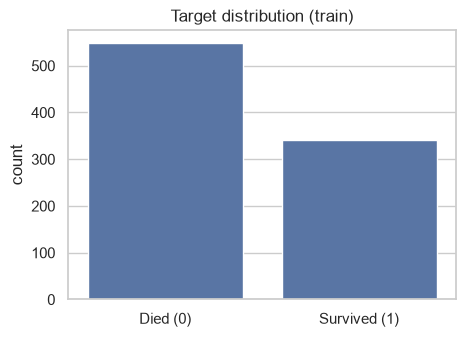

In [8]:
survival_rate = train["Survived"].mean()
print(f"Survival rate: {survival_rate:.1%}")
print(f"Accuracy of always predicting 'died': {1 - survival_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=train, x="Survived", ax=ax)
ax.set_xticks([0, 1], ["Died (0)", "Survived (1)"])
ax.set_xlabel("")
ax.set_title("Target distribution (train)")
save_fig(fig, "target_distribution")
plt.show()

## 4. Categorical features: Sex, Pclass, Embarked

In [9]:
for col in ["Sex", "Pclass", "Embarked"]:
    display(survival_table(train, col))

,count,survival_rate
Sex,,
female,314,0.742
male,577,0.189


,count,survival_rate
Pclass,,
1,216,0.630
2,184,0.473
3,491,0.242


,count,survival_rate
Embarked,,
C,168,0.554
Q,77,0.390
S,644,0.337
NaN,2,1.000


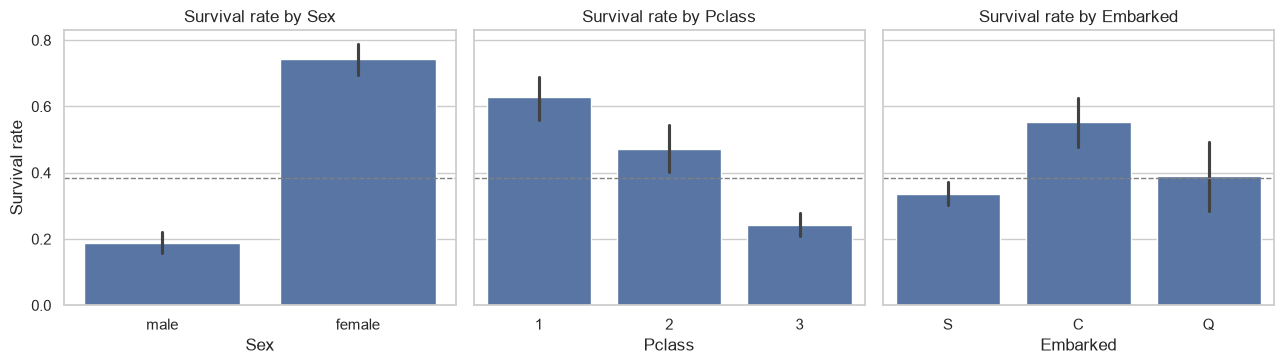

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, col in zip(axes, ["Sex", "Pclass", "Embarked"]):
    sns.barplot(data=train, x=col, y="Survived", ax=ax, errorbar=("ci", 95))
    ax.axhline(survival_rate, ls="--", c="grey", lw=1)
    ax.set_title(f"Survival rate by {col}")
axes[0].set_ylabel("Survival rate")
fig.tight_layout()
save_fig(fig, "survival_by_category")
plt.show()

The dashed line is the overall survival rate. Black bars are 95% confidence intervals: wide bars mean few passengers in that group.

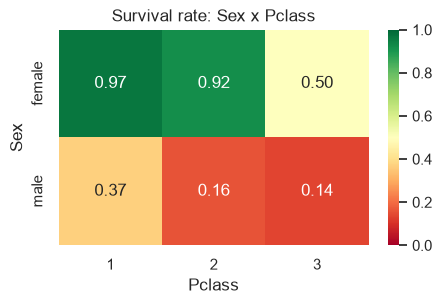

In [11]:
sex_class = train.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean")

fig, ax = plt.subplots(figsize=(5, 2.8))
sns.heatmap(sex_class, annot=True, fmt=".2f", cmap="RdYlGn", vmin=0, vmax=1, ax=ax)
ax.set_title("Survival rate: Sex x Pclass")
save_fig(fig, "survival_sex_pclass")
plt.show()

## 5. Numeric features: Age and Fare

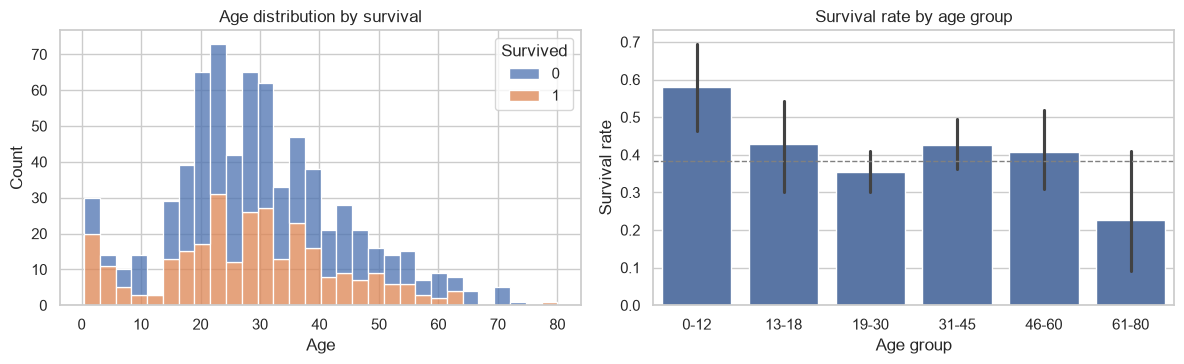

,count,survival_rate
AgeGroup,,
0-12,69,0.580
13-18,70,0.429
19-30,270,0.356
31-45,202,0.426
46-60,81,0.407
61-80,22,0.227
NaN,177,0.294


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=train, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[0])
axes[0].set_title("Age distribution by survival")

age_bins = pd.cut(train["Age"], bins=[0, 12, 18, 30, 45, 60, 80],
                  labels=["0-12", "13-18", "19-30", "31-45", "46-60", "61-80"])
sns.barplot(x=age_bins, y=train["Survived"], ax=axes[1])
axes[1].axhline(survival_rate, ls="--", c="grey", lw=1)
axes[1].set_xlabel("Age group")
axes[1].set_ylabel("Survival rate")
axes[1].set_title("Survival rate by age group")
fig.tight_layout()
save_fig(fig, "age")
plt.show()

survival_table(train.assign(AgeGroup=age_bins), "AgeGroup")

Fare skewness: 4.79
Passengers with Fare == 0: 15


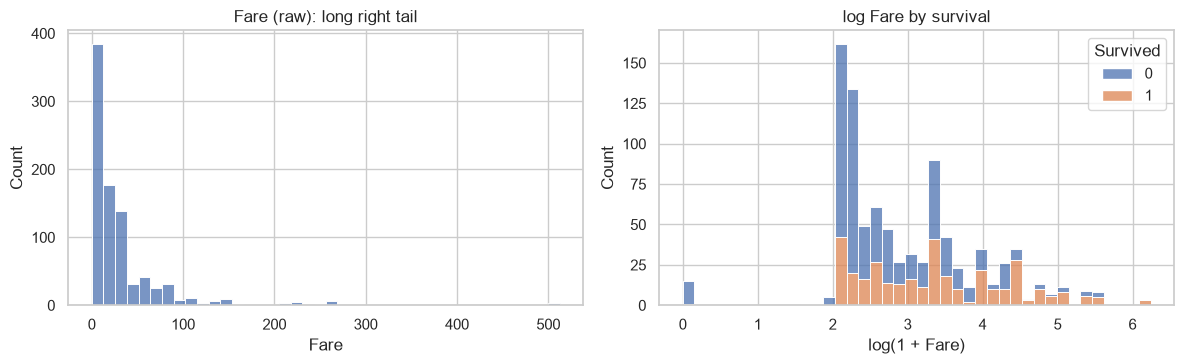

,count,survival_rate
FareQuartile,,
"(-0.001, 7.91]",223,0.197
"(7.91, 14.454]",224,0.304
"(14.454, 31.0]",222,0.455
"(31.0, 512.329]",222,0.581


In [13]:
print("Fare skewness:", round(train["Fare"].skew(), 2))
print("Passengers with Fare == 0:", (train["Fare"] == 0).sum())

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(data=train, x="Fare", bins=40, ax=axes[0])
axes[0].set_title("Fare (raw): long right tail")
sns.histplot(x=np.log1p(train["Fare"]), hue=train["Survived"], bins=40,
             multiple="stack", ax=axes[1])
axes[1].set_xlabel("log(1 + Fare)")
axes[1].set_title("log Fare by survival")
fig.tight_layout()
save_fig(fig, "fare")
plt.show()

survival_table(train.assign(FareQuartile=pd.qcut(train["Fare"], 4)), "FareQuartile")

In [14]:
train.groupby("Pclass")["Fare"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
Pclass,,,,,,,,
1,216.0,84.2,78.4,0.0,30.9,60.3,93.5,512.3
2,184.0,20.7,13.4,0.0,13.0,14.2,26.0,73.5
3,491.0,13.7,11.8,0.0,7.8,8.0,15.5,69.6


## 6. Feature ideas

Everything below is built on a copy (`eda`), so the raw data stays untouched.
In the modelling notebooks these steps will live inside a scikit-learn `Pipeline`.

In [15]:
eda = train.copy()

# Family size: the passenger plus siblings/spouses plus parents/children
eda["FamilySize"] = eda["SibSp"] + eda["Parch"] + 1
eda["FamilyType"] = pd.cut(eda["FamilySize"], bins=[0, 1, 4, 11],
                           labels=["alone", "small (2-4)", "large (5+)"])

display(survival_table(eda, "FamilySize"))
survival_table(eda, "FamilyType")

,count,survival_rate
FamilySize,,
1,537,0.304
2,161,0.553
3,102,0.578
4,29,0.724
5,15,0.200
6,22,0.136
7,12,0.333
8,6,0.000
11,7,0.000


,count,survival_rate
FamilyType,,
alone,537,0.304
small (2-4),292,0.579
large (5+),62,0.161


In [16]:
# Title is the word between the comma and the dot: "Braund, Mr. Owen Harris" -> "Mr"
eda["Title"] = eda["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
eda["Title"].value_counts()

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Major             2
Mlle              2
Col               2
Don               1
Mme               1
Ms                1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

In [17]:
title_map = {"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}
eda["Title"] = eda["Title"].replace(title_map)
common_titles = ["Mr", "Mrs", "Miss", "Master"]
eda["Title"] = eda["Title"].where(eda["Title"].isin(common_titles), "Rare")

display(survival_table(eda, "Title"))

# Title also tells us a lot about age, which helps fill missing Age values
eda.groupby("Title")["Age"].agg(["count", "median", "mean"]).round(1)

,count,survival_rate
Title,,
Master,40,0.575
Miss,185,0.703
Mr,517,0.157
Mrs,126,0.794
Rare,23,0.348


,count,median,mean
Title,,,
Master,36,3.5,4.6
Miss,149,21.0,21.8
Mr,398,30.0,32.4
Mrs,109,35.0,35.8
Rare,22,48.5,45.5


In [18]:
eda["HasCabin"] = eda["Cabin"].notna().astype(int)
eda["Deck"] = eda["Cabin"].str[0].fillna("Unknown")

display(survival_table(eda, "HasCabin"))
pd.crosstab(eda["Deck"], eda["Pclass"])

,count,survival_rate
HasCabin,,
0,687,0.300
1,204,0.667


Pclass,1,2,3
Deck,,,
A,15,0,0
B,47,0,0
C,59,0,0
D,29,4,0
E,25,4,3
F,0,8,5
G,0,0,4
T,1,0,0
Unknown,40,168,479


In [19]:
# How many passengers in train share the same ticket (groups travelling together)
eda["TicketGroupSize"] = eda.groupby("Ticket")["Ticket"].transform("size")
survival_table(eda, "TicketGroupSize")

,count,survival_rate
TicketGroupSize,,
1,547,0.298
2,188,0.574
3,63,0.698
4,44,0.500
5,10,0.000
6,18,0.000
7,21,0.238


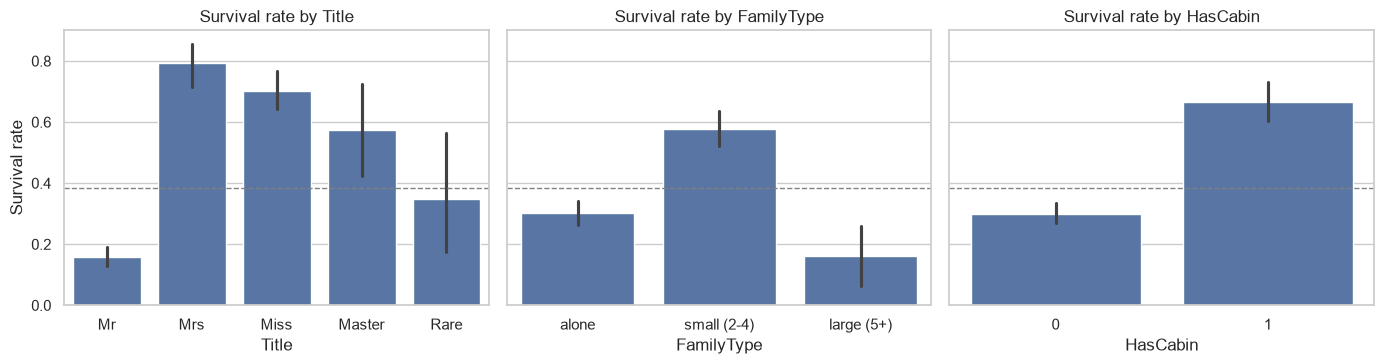

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, col in zip(axes, ["Title", "FamilyType", "HasCabin"]):
    sns.barplot(data=eda, x=col, y="Survived", ax=ax)
    ax.axhline(survival_rate, ls="--", c="grey", lw=1)
    ax.set_title(f"Survival rate by {col}")
axes[0].set_ylabel("Survival rate")
fig.tight_layout()
save_fig(fig, "engineered_features")
plt.show()

## 7. Correlations

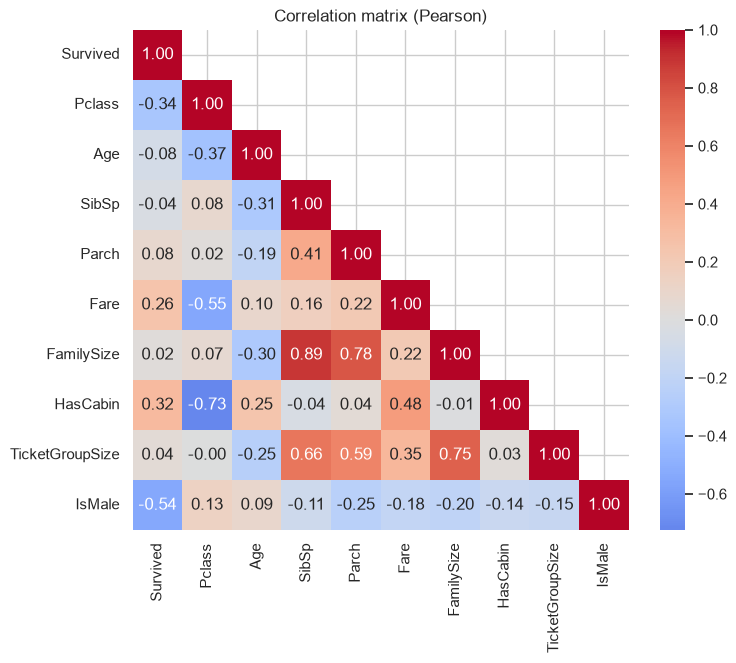

IsMale            -0.543
Pclass            -0.338
HasCabin           0.317
Fare               0.257
Parch              0.082
Age               -0.077
TicketGroupSize    0.038
SibSp             -0.035
FamilySize         0.017
Name: Survived, dtype: float64

In [21]:
corr_cols = ["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare",
             "FamilySize", "HasCabin", "TicketGroupSize"]
corr = eda.assign(IsMale=(eda["Sex"] == "male").astype(int))[corr_cols + ["IsMale"]].corr()

fig, ax = plt.subplots(figsize=(8, 6.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (Pearson)")
save_fig(fig, "correlation")
plt.show()

corr["Survived"].drop("Survived").sort_values(key=abs, ascending=False).round(3)

Pearson correlation only measures *linear* relationships. `FamilySize`, for example, has a
low correlation even though section 6 shows a clear pattern (small families did best, both
alone and large families did worse). Tree models can pick up such non-linear patterns.

## 8. Train vs test: same distribution?

In [22]:
for col in ["Sex", "Pclass", "Embarked"]:
    comparison = pd.DataFrame({
        "train": train[col].value_counts(normalize=True),
        "test": test[col].value_counts(normalize=True),
    }).round(3)
    display(comparison)

,train,test
Sex,,
male,0.648,0.636
female,0.352,0.364


,train,test
Pclass,,
3,0.551,0.522
1,0.242,0.256
2,0.207,0.222


,train,test
Embarked,,
S,0.724,0.646
C,0.189,0.244
Q,0.087,0.110


In [23]:
pd.DataFrame({
    "train": train[["Age", "Fare", "SibSp", "Parch"]].describe().loc[["mean", "50%", "std"]].stack(),
    "test": test[["Age", "Fare", "SibSp", "Parch"]].describe().loc[["mean", "50%", "std"]].stack(),
}).round(2)

train   test
mean Age    29.70  30.27
     Fare   32.20  35.63
     SibSp   0.52   0.45
     Parch   0.38   0.39
50%  Age    28.00  27.00
     Fare   14.45  14.45
     SibSp   0.00   0.00
     Parch   0.00   0.00
std  Age    14.53  14.18
     Fare   49.69  55.91
     SibSp   1.10   0.90
     Parch   0.81   0.98

## 9. Findings

**Data quality**
- 891 training and 418 test passengers, no duplicate rows, no shared `PassengerId`.
- `Cabin` is missing for 77% of passengers, so the cabin number itself is unusable. Whether a cabin is recorded at all
  (`HasCabin`) is informative: 66.7% survival with a cabin vs 30.0% without. Deck letters A–C occur only in 1st class.
- `Age` is missing for ~20% (train and test). Passengers with missing age survived less often (29.4%), so the
  missingness itself is worth a flag (`AgeMissing`).
- `Embarked` is missing for 2 train rows, `Fare` for 1 test row. Simple imputation is enough.

**Target**
- 38.4% survived. Always predicting "died" already gives **61.6% accuracy**: every model must beat this.

**Strongest signals**
- **Sex:** 74.2% of women survived vs 18.9% of men.
- **Class:** 63.0% (1st), 47.3% (2nd), 24.2% (3rd).
- **Sex x class:** women in 1st/2nd class survived at 97%/92%, women in 3rd class at 50%; men in 2nd/3rd class at
  only 16%/14%. "Women and children first", strongly modulated by class.
- **Title** (from `Name`) combines sex and age: Mr 15.7%, Mrs 79.4%, Miss 70.3%, Master 57.5%. `Master` marks boys,
  which `Sex` alone cannot separate from men. Median age per title (Master 3.5, Miss 21, Mr 30, Mrs 35) makes it a
  good basis for filling missing ages.

**Weaker or non-linear signals**
- **Age:** children 0–12 survived at 58%, passengers 61+ at 23%, the groups in between at 36–43%.
- **Fare:** very skewed (skewness 4.8, 15 zero fares). Survival rises from 19.7% in the cheapest to 58.1% in the most
  expensive quartile, but fare largely overlaps with class. A log transform helps linear models.
- **Family size:** alone 30.4%, small families (2–4) 57.9%, large families (5+) 16.1%. The Pearson correlation is
  almost zero (0.017) because the pattern is an inverted U. Binning helps linear models; trees can learn it directly.
  Ticket group size shows the same shape.
- **Embarked:** Cherbourg 55.4% vs Southampton 33.7%. Partly a class effect (51% of Cherbourg passengers were 1st
  class vs 20% from Southampton), but the gap remains within 3rd class (37.9% vs 19.0%).

**Train vs test**
- Sex, class, age and fare distributions are very close. Test has a few more Cherbourg passengers (24% vs 19%).
  No sign that test comes from a different population.

**Plan for the baseline (notebook 02)**
- Features: `Pclass`, `Sex`, `Title`, `Age` (imputed by title) + `AgeMissing`, `log1p(Fare)`, `FamilyType`,
  `HasCabin`, `Embarked`. Dropped: `PassengerId`, raw `Name`, `Ticket`, `Cabin`.
- Every learned step (imputation medians, scaling, one-hot categories) goes inside a scikit-learn `Pipeline`, so it
  is fitted on the training folds only. Computing them on all data before cross-validation would leak information.
- Evaluation: 5-fold `StratifiedKFold`, reported as mean ± std accuracy, compared against the 61.6% majority baseline.